In [1]:
import os
from pathlib import Path

# Set COVID_CT_DATA_DIR to the dataset root when running outside the default Kaggle path.
DATA_DIR = DATA_DIR = Path("/kaggle/input")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset directory not found: {DATA_DIR}. "
        "Set the COVID_CT_DATA_DIR environment variable to the dataset root."
    )

print("Dataset root:", DATA_DIR)
print("Top-level folder structure:")
for item in DATA_DIR.iterdir():
    print(item.name, "->", item)


Dataset root: /kaggle/input
Top-level folder structure:
datasets -> /kaggle/input/datasets


In [2]:
from collections import Counter
from pathlib import Path

DATA_DIR = Path("/kaggle/input")

extensions = Counter()
sample_files = []
total_files = 0

for path in DATA_DIR.rglob("*"):
    if path.is_file():
        total_files += 1
        extensions[path.suffix.lower() or "[no extension]"] += 1

        if len(sample_files) < 50:
            sample_files.append(path)

print("Total files:", total_files)

print("\nFile types:")
for extension, count in extensions.most_common():
    print(f"{extension}: {count}")


Total files: 12074

File types:
.tif: 12058
.csv: 16


In [3]:
for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".csv", ".json", ".txt", ".xlsx"
    }:
        print(path.relative_to(DATA_DIR))

datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/train4.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/validation2.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/validation4.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/validation3.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/test1.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/train3.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/test5.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/test4.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/train1.csv
datasets/mohammadrahimzadeh/covidctset-a-large-covid19-ct-scans-dataset/Annotation/CSV/train5.csv
datasets

In [4]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/datasets/mohammadrahimzadeh/"
    "covidctset-a-large-covid19-ct-scans-dataset"
)
CSV_DIR = DATA_DIR / "Annotation" / "CSV"

for csv_path in sorted(CSV_DIR.glob("*.csv")):
    df = pd.read_csv(csv_path)

    print(f"\n{'=' * 60}")
    print("File:", csv_path.name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


File: Patient_details.csv
Shape: (377, 5)
Columns: ['Patient ID', 'SEX', 'AGE', 'Date', 'COVID-19 Infection']
Patient ID SEX  AGE     Date COVID-19 Infection
  patient1   F 053Y 20200407           Positive
  patient3   M 066Y 20200418           Positive
  patient5   M 035Y 20200328           Positive

File: test1.csv
Shape: (8322, 2)
Columns: ['filename', 'class']
                            filename class
137covid_patient100_SR_2_IM00028.tif covid
137covid_patient100_SR_2_IM00029.tif covid
137covid_patient100_SR_2_IM00045.tif covid

File: test2.csv
Shape: (8343, 2)
Columns: ['filename', 'class']
                          filename class
137covid_patient1_SR_2_IM00010.tif covid
137covid_patient1_SR_2_IM00011.tif covid
137covid_patient1_SR_2_IM00012.tif covid

File: test3.csv
Shape: (8329, 2)
Columns: ['filename', 'class']
                           filename class
137covid_patient54_SR_2_IM00028.tif covid
137covid_patient54_SR_2_IM00029.tif covid
137covid_patient54_SR_2_IM00030.tif covi

In [5]:
import re
import pandas as pd
from pathlib import Path

CSV_DIR = DATA_DIR / "Annotation" / "CSV"

# --------------------------------------------------
# 1. Index all available TIFF files by filename
# --------------------------------------------------
image_paths = {}

for path in DATA_DIR.rglob("*"):
    if path.is_file() and path.suffix.lower() in {".tif", ".tiff"}:
        image_paths.setdefault(path.name, []).append(path)

print("Unique TIFF filenames:", len(image_paths))

# --------------------------------------------------
# 2. Load each CSV and inspect labels
# --------------------------------------------------
splits = {}

for split in ["train", "validation", "test"]:
    for fold in range(1, 6):
        name = f"{split}{fold}"
        df = pd.read_csv(CSV_DIR / f"{name}.csv")

        df["filename"] = df["filename"].astype(str).str.strip()
        df["class"] = df["class"].astype(str).str.strip().str.lower()

        # Extract patient number from filenames such as
        # 137covid_patient100_SR_2_IM00028.tif
        df["patient_id"] = df["filename"].str.extract(
            r"(patient\d+)", flags=re.IGNORECASE
        )[0].str.lower()

        splits[name] = df

        print(f"\n{name}: {len(df)} rows")
        print("Class counts:")
        print(df["class"].value_counts(dropna=False).to_dict())
        print("Unique filenames:", df["filename"].nunique())
        print("Missing patient IDs:", df["patient_id"].isna().sum())

# --------------------------------------------------
# 3. Check whether CSV filenames exist on disk
# --------------------------------------------------
print("\n" + "=" * 65)
print("FILE EXISTENCE AUDIT")

for name, df in splits.items():
    missing = sorted(set(df["filename"]) - set(image_paths))
    print(
        f"{name}: {len(missing)} filenames missing "
        f"out of {df['filename'].nunique()} unique filenames"
    )

    if missing:
        print("  Examples:", missing[:5])

# --------------------------------------------------
# 4. Check overlap within each numbered fold
# --------------------------------------------------
print("\n" + "=" * 65)
print("WITHIN-FOLD OVERLAP AUDIT")

for fold in range(1, 6):
    train = splits[f"train{fold}"]
    val = splits[f"validation{fold}"]
    test = splits[f"test{fold}"]

    print(f"\nFOLD {fold}")

    # Compare unique filenames
    for name_a, df_a, name_b, df_b in [
        ("train", train, "validation", val),
        ("train", train, "test", test),
        ("validation", val, "test", test),
    ]:
        overlap = set(df_a["filename"]) & set(df_b["filename"])
        print(
            f"{name_a} vs {name_b}: "
            f"{len(overlap)} overlapping filenames"
        )
        if overlap:
            print("  Examples:", list(sorted(overlap))[:3])

    # Compare patient IDs
    for name_a, df_a, name_b, df_b in [
        ("train", train, "validation", val),
        ("train", train, "test", test),
        ("validation", val, "test", test),
    ]:
        patients_a = set(df_a["patient_id"].dropna())
        patients_b = set(df_b["patient_id"].dropna())
        overlap = patients_a & patients_b

        print(
            f"{name_a} vs {name_b}: "
            f"{len(overlap)} overlapping patients"
        )
        if overlap:
            print("  Examples:", sorted(overlap)[:5])

# --------------------------------------------------
# 5. Inspect patient diagnosis metadata
# --------------------------------------------------
print("\n" + "=" * 65)
print("PATIENT DIAGNOSIS AUDIT")

patient_details = pd.read_csv(CSV_DIR / "Patient_details.csv")

print("Patient metadata rows:", len(patient_details))
print(
    patient_details["COVID-19 Infection"]
    .value_counts(dropna=False)
    .to_dict()
)

print("\nSample patient records:")
print(patient_details.head().to_string(index=False))

Unique TIFF filenames: 12058

train1: 3736 rows
Class counts:
{'normal': 1916, 'covid': 1820}
Unique filenames: 3736
Missing patient IDs: 0

train2: 3715 rows
Class counts:
{'normal': 1898, 'covid': 1817}
Unique filenames: 3715
Missing patient IDs: 0

train3: 3729 rows
Class counts:
{'normal': 1893, 'covid': 1836}
Unique filenames: 3729
Missing patient IDs: 0

train4: 3743 rows
Class counts:
{'normal': 1920, 'covid': 1823}
Unique filenames: 3743
Missing patient IDs: 0

train5: 3823 rows
Class counts:
{'normal': 1991, 'covid': 1832}
Unique filenames: 3823
Missing patient IDs: 0

validation1: 912 rows
Class counts:
{'covid': 462, 'normal': 450}
Unique filenames: 912
Missing patient IDs: 0

validation2: 915 rows
Class counts:
{'covid': 465, 'normal': 450}
Unique filenames: 915
Missing patient IDs: 0

validation3: 896 rows
Class counts:
{'normal': 450, 'covid': 446}
Unique filenames: 896
Missing patient IDs: 0

validation4: 909 rows
Class counts:
{'covid': 459, 'normal': 450}
Unique filena

In [6]:
import re
import pandas as pd
from pathlib import Path

CSV_DIR = DATA_DIR / "Annotation" / "CSV"

# Load every supplied split
frames = []

for split in ["train", "validation", "test"]:
    for fold in range(1, 6):
        df = pd.read_csv(CSV_DIR / f"{split}{fold}.csv")
        df["source_split"] = f"{split}{fold}"
        frames.append(df)

all_rows = pd.concat(frames, ignore_index=True)

# Extract patient ID from each filename
all_rows["patient_id"] = (
    all_rows["filename"]
    .str.extract(r"(patient\d+)", flags=re.IGNORECASE)[0]
    .str.lower()
)

all_rows["class"] = all_rows["class"].str.strip().str.lower()

print("CSV rows across all folds:", len(all_rows))
print("Unique filenames:", all_rows["filename"].nunique())
print("Missing patient IDs:", all_rows["patient_id"].isna().sum())

# Check whether the same image receives conflicting labels
label_counts = all_rows.groupby("filename")["class"].nunique()
conflicting_images = label_counts[label_counts > 1]

print("\nImages with conflicting labels:", len(conflicting_images))

# Stop rather than silently choosing an arbitrary label for conflicting images.
if not conflicting_images.empty:
    examples = conflicting_images.index[:10].tolist()
    raise ValueError(
        f"Found {len(conflicting_images)} images with conflicting labels. "
        f"Resolve these annotations before training. Examples: {examples}"
    )

# Create one row per image after confirming its label is unambiguous.
manifest = (
    all_rows[["filename", "patient_id", "class"]]
    .drop_duplicates()
    .drop_duplicates(subset="filename")
    .reset_index(drop=True)
)

print("\nUnique image manifest:", manifest.shape)
print("Image class counts:")
print(manifest["class"].value_counts())

# Compare labels with patient diagnosis metadata
patient_details = pd.read_csv(CSV_DIR / "Patient_details.csv")

patient_details["patient_id"] = (
    patient_details["Patient ID"].str.lower()
)

diagnosis_map = {
    "positive": "covid",
    "negative": "normal"
}

patient_details["metadata_class"] = (
    patient_details["COVID-19 Infection"]
    .str.strip()
    .str.lower()
    .map(diagnosis_map)
)

manifest = manifest.merge(
    patient_details[["patient_id", "metadata_class"]],
    on="patient_id",
    how="left",
    validate="many_to_one"
)

print("\nImages without matching patient metadata:",
      manifest["metadata_class"].isna().sum())

mismatches = manifest[
    manifest["metadata_class"].notna()
    & (manifest["class"] != manifest["metadata_class"])
]

print("Image/metadata label mismatches:", len(mismatches))

# Check for patients with multiple image labels
patient_label_counts = manifest.groupby("patient_id")["class"].nunique()
mixed_patients = patient_label_counts[patient_label_counts > 1]

print("Patients with mixed image labels:", len(mixed_patients))

print("\nPatients represented:", manifest["patient_id"].nunique())
print("Patient diagnosis counts:")
print(patient_details["metadata_class"].value_counts(dropna=False))


CSV rows across all folds: 64822
Unique filenames: 12058
Missing patient IDs: 0

Images with conflicting labels: 0

Unique image manifest: (12058, 3)
Image class counts:
class
normal    9776
covid     2282
Name: count, dtype: int64

Images without matching patient metadata: 0
Image/metadata label mismatches: 0
Patients with mixed image labels: 0

Patients represented: 377
Patient diagnosis counts:
metadata_class
normal    282
covid      95
Name: count, dtype: int64


File: 157covid_patient141_SR_3_IM00016.tif | Class: covid | Shape: (512, 512) | Dtype: uint16 | Range: 0–3328
File: 137covid_patient85_SR_4_IM00084.tif | Class: covid | Shape: (512, 512) | Dtype: uint16 | Range: 0–2392
File: 157covid_patient133_SR_2_IM00030.tif | Class: covid | Shape: (512, 512) | Dtype: uint16 | Range: 0–2657
File: normalcd3_patient419_SR_2_IM00039.tif | Class: normal | Shape: (512, 512) | Dtype: uint16 | Range: 0–2343
File: normalcd2_patient417_SR_2_IM00038.tif | Class: normal | Shape: (512, 512) | Dtype: uint16 | Range: 0–2730
File: normal1_patient242_SR_2_IM00032.tif | Class: normal | Shape: (512, 512) | Dtype: uint16 | Range: 0–2243


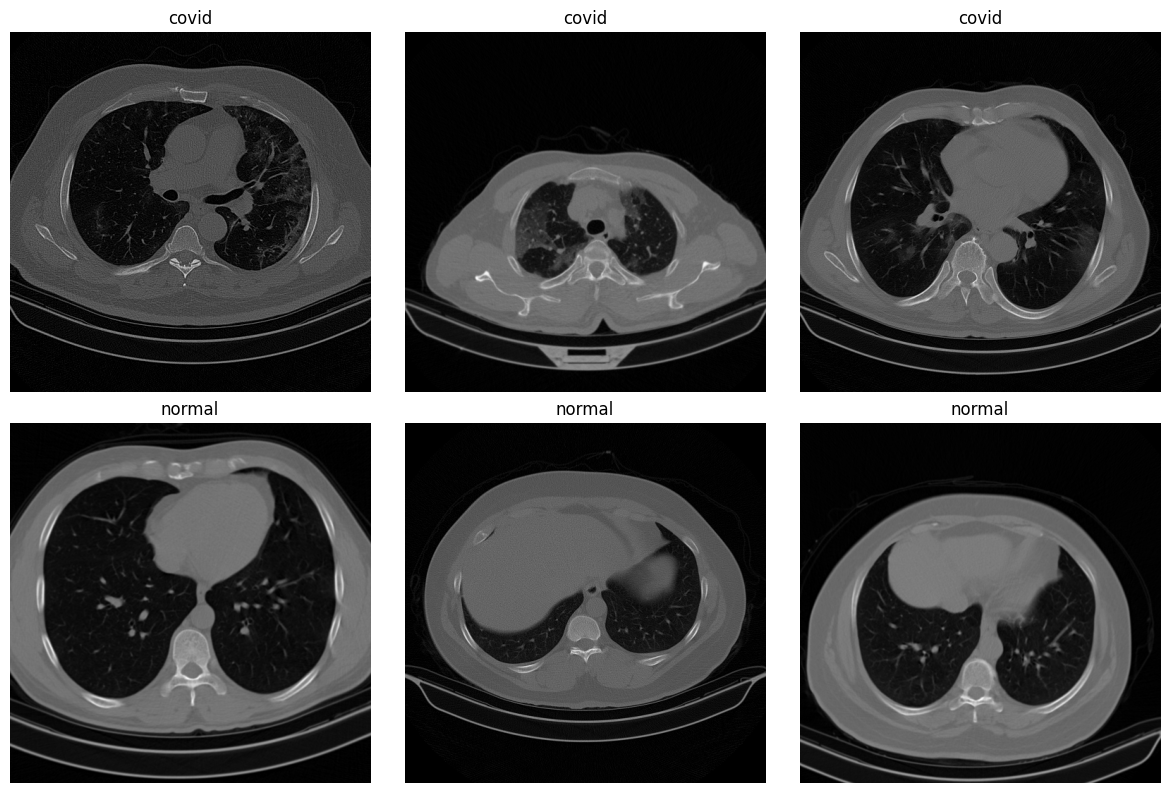

In [7]:
import random
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

sample = (
    manifest.groupby("class", group_keys=False)
    .sample(n=3, random_state=42)
    .reset_index(drop=True)
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    paths = image_paths[row["filename"]]
    image_path = paths[0]

    with Image.open(image_path) as img:
        image = np.array(img)

    print(
        f"File: {row['filename']} | "
        f"Class: {row['class']} | "
        f"Shape: {image.shape} | "
        f"Dtype: {image.dtype} | "
        f"Range: {image.min()}–{image.max()}"
    )

    ax.imshow(image, cmap="gray")
    ax.set_title(row["class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

# One row per patient
patients = (
    manifest[["patient_id", "metadata_class"]]
    .drop_duplicates()
    .dropna()
    .reset_index(drop=True)
)

assert patients["patient_id"].is_unique
assert patients["metadata_class"].isin(["covid", "normal"]).all()

# 70% training patients, 15% validation, 15% test
train_patients, remaining_patients = train_test_split(
    patients,
    test_size=0.30,
    random_state=42,
    stratify=patients["metadata_class"]
)

val_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=0.50,
    random_state=42,
    stratify=remaining_patients["metadata_class"]
)

train_ids = set(train_patients["patient_id"])
val_ids = set(val_patients["patient_id"])
test_ids = set(test_patients["patient_id"])

# Verify no patient appears in multiple splits
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Assign images using their patient IDs
train_df = manifest[manifest["patient_id"].isin(train_ids)].copy()
val_df = manifest[manifest["patient_id"].isin(val_ids)].copy()
test_df = manifest[manifest["patient_id"].isin(test_ids)].copy()

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print("Patients:", df["patient_id"].nunique())
    print("Images:", len(df))
    print("Image classes:")
    print(df["class"].value_counts())

print("\nAll patient-overlap checks passed.")


TRAIN
Patients: 263
Images: 8476
Image classes:
class
normal    6827
covid     1649
Name: count, dtype: int64

VALIDATION
Patients: 57
Images: 1915
Image classes:
class
normal    1544
covid      371
Name: count, dtype: int64

TEST
Patients: 57
Images: 1667
Image classes:
class
normal    1405
covid      262
Name: count, dtype: int64

All patient-overlap checks passed.


In [9]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)   # if this says cpu: Kaggle Settings -> Accelerator -> GPU
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.11.0+cpu


In [10]:
class COVIDCTDataset(Dataset):
    def __init__(self, dataframe, image_paths, image_size=224, train=False):
        self.df = dataframe.reset_index(drop=True)
        self.image_paths = image_paths
        self.image_size = image_size
        self.train = train
        self.label_map = {"normal": 0, "covid": 1}

        # small rotations / shifts / zoom, applied to training images only
        self.augment = T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1))

        self.mean = torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_path = self.image_paths[row["filename"]][0]

        with Image.open(image_path) as img:
            image = np.array(img, dtype=np.float32)

        # robust intensity scaling (same as your baseline)
        low, high = np.percentile(image, [0.5, 99.5])
        if high > low:
            image = np.clip(image, low, high)
            image = (image - low) / (high - low)
        else:
            image = np.zeros_like(image, dtype=np.float32)

        image = torch.from_numpy(image.copy()).unsqueeze(0)        # [1, 512, 512]

        # antialias=True avoids aliasing when shrinking 512 -> 224
        image = F.interpolate(image.unsqueeze(0), size=(self.image_size, self.image_size),
                              mode="bilinear", align_corners=False, antialias=True).squeeze(0)

        if self.train:
            image = self.augment(image)

        image = image.repeat(3, 1, 1).to(torch.float32)            # [3, 224, 224]
        image = (image - self.mean) / self.std

        label = torch.tensor(self.label_map[row["class"]], dtype=torch.float32)
        return image, label

In [11]:
train_dataset = COVIDCTDataset(train_df, image_paths, train=True)
val_dataset = COVIDCTDataset(val_df, image_paths)
test_dataset = COVIDCTDataset(test_df, image_paths)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True,
                          num_workers=2, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False,
                        num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False,
                         num_workers=2, pin_memory=torch.cuda.is_available())

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label values:", labels.unique().tolist())

Image batch shape: torch.Size([16, 3, 224, 224])
Label values: [0.0, 1.0]


In [12]:
def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(cout),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )


class BaselineCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            block(3, 32),      # 112
            block(32, 64),     # 56
            block(64, 128),    # 28
            block(128, 256),   # 14
            block(256, 256),   # 7
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)   # raw logits

In [13]:
from collections import Counter

class_counts = train_df["class"].value_counts()

negative_count = int(class_counts["normal"])
positive_count = int(class_counts["covid"])

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

print("Normal images:", negative_count)
print("COVID images:", positive_count)
print("Positive class weight:", pos_weight.item())

Normal images: 6827
COVID images: 1649
Positive class weight: 4.140084743499756


In [14]:
model = BaselineCNN().to(device)

# BCEWithLogitsLoss takes raw logits and applies the sigmoid internally (more stable than
# sigmoid + BCELoss). pos_weight makes a missed COVID slice ~4x as costly, which fixes the
# low recall you saw. Do NOT also use WeightedRandomSampler, that would double-count.
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 979489


In [ ]:
from sklearn.metrics import roc_auc_score

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
  
    
    total_loss, total = 0.0, 0
    all_probs, all_labels = [], []
    
    for images, labels in loader:
        images = images.to(device=device, dtype=torch.float32)
        labels = labels.to(device=device, dtype=torch.float32)
        
        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total += labels.size(0)
        all_probs.append(torch.sigmoid(logits).detach().cpu())
        all_labels.append(labels.cpu())

    probs = torch.cat(all_probs).numpy()
    labels = torch.cat(all_labels).numpy()
    return total_loss / total, roc_auc_score(labels, probs)


EPOCHS = 5
PATIENCE = 4                      # stop if val AUC has not improved for 4 epochs
best_auc, bad_epochs = 0.0, 0

for epoch in range(EPOCHS):
    train_loss, train_auc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_auc = run_epoch(model, val_loader, criterion)
    
    saved = ""
    if val_auc > best_auc:
        best_auc, bad_epochs = val_auc, 0
        torch.save(model.state_dict(), "best_cnn.pt")
        saved = "  <- saved"
    else:
        bad_epochs += 1

    print(f"Epoch {epoch + 1}/{EPOCHS} | Train Loss: {train_loss:.4f} AUC: {train_auc:.3f} | "
          f"Val Loss: {val_loss:.4f} AUC: {val_auc:.3f}{saved}")

    if bad_epochs >= PATIENCE:
        print("Early stopping.")
        break

Epoch 1/5 | Train Loss: 0.3835 AUC: 0.966 | Val Loss: 0.4359 AUC: 0.975  <- saved
Epoch 2/5 | Train Loss: 0.3273 AUC: 0.975 | Val Loss: 1.4556 AUC: 0.964


In [ ]:
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve)

model.load_state_dict(torch.load("best_cnn.pt", map_location=device))

@torch.no_grad()
def get_probs(loader):
    model.eval()
    probs = []
    for images, _ in loader:
        probs.append(torch.sigmoid(model(images.to(device=device, dtype=torch.float32))).cpu())
    return torch.cat(probs).numpy()

val_labels = (val_df["class"] == "covid").astype(int).to_numpy()
val_probs = get_probs(val_loader)
val_preds = (val_probs >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(val_labels, val_preds), 4))
print("\nConfusion Matrix:\n", confusion_matrix(val_labels, val_preds))
print("\nClassification Report:")
print(classification_report(val_labels, val_preds, labels=[0, 1],
                            target_names=["Normal", "COVID"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(val_labels, val_probs), 4))

In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
results = []

for threshold in thresholds:
    predictions = (val_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if tp + fn else 0
    specificity = tn / (tn + fp) if tn + fp else 0
    precision = tp / (tp + fp) if tp + fp else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy, 4),
        "Sensitivity": round(sensitivity, 4),
        "Specificity": round(specificity, 4),
        "Precision": round(precision, 4),
        "False Negatives": int(fn),
        "False Positives": int(fp)
    })

threshold_df = pd.DataFrame(results)
print(threshold_df.to_string(index=False))

In [ ]:
# Choose the operating threshold on VALIDATION data: the highest threshold that still
# catches at least TARGET_SENSITIVITY of COVID slices.
TARGET_SENSITIVITY = 0.85

fpr, tpr, thr = roc_curve(val_labels, val_probs)
chosen_threshold = float(thr[np.where(tpr >= TARGET_SENSITIVITY)[0][0]])
print("Chosen threshold:", round(chosen_threshold, 3))

In [ ]:
# Run this ONCE, after you are done changing the model. Threshold comes from validation.
test_labels = (test_df["class"] == "covid").astype(int).to_numpy()
test_probs = get_probs(test_loader)
test_preds = (test_probs >= chosen_threshold).astype(int)

print("=== TEST, per slice ===")
print(confusion_matrix(test_labels, test_preds))
print(classification_report(test_labels, test_preds, target_names=["Normal", "COVID"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(test_labels, test_probs), 4))

# The diagnosis belongs to the PATIENT, so average the slice scores per patient.
patient_scores = (pd.DataFrame({"patient_id": test_df["patient_id"].values,
                                "label": test_labels, "prob": test_probs})
                  .groupby("patient_id").agg(label=("label", "first"), prob=("prob", "mean")))

patient_preds = (patient_scores["prob"] >= chosen_threshold).astype(int)
print("\n=== TEST, per patient (mean slice probability) ===")
print(confusion_matrix(patient_scores["label"], patient_preds))
print("Patient ROC-AUC:", round(roc_auc_score(patient_scores["label"], patient_scores["prob"]), 4),
      f"({len(patient_scores)} patients, so expect noisy numbers)")